In [1]:
import math
import os
import glob

import onnx
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

import onnx2tf
import tensorflow as tf
print("TensorFlow version: ", tf.__version__)

TensorFlow version:  2.17.0


In [2]:
def load_model(model_path):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()
    return interpreter

In [3]:
def model2onnx(file_path: str, model: nn.Module, x: list[np.ndarray], simplify=False):
    os.makedirs(os.path.dirname(file_path), exist_ok=True)

    torch.onnx.export(
        model,
        tuple(torch.Tensor(i) for i in x),
        file_path,
        input_names=[f"input_{i}" for i in range(len(x))],
        output_names=["output_0"],
    )

    if simplify:
        import onnxslim

        model_onnx = onnx.load(file_path)
        model_onnx = onnxslim.slim(model_onnx)
        onnx.save(model_onnx, file_path)

In [4]:
class Dummy(nn.Module):
    def __init__(self):
        super().__init__()
        self.sigm = nn.Sigmoid()

    def forward(self, x0, x1, x2):
        y = torch.permute(torch.cat([x0, x1, x2], 1), (0, 2, 1))
        return self.sigm(y)

(100, 1600, 64) -6.45965 16.104881
(100, 100, 64) -0.4463123 2.3295326
(100, 100, 1) -13.692745 -11.383772
(100, 1600, 1) -55.141174 1.793209
(100, 400, 1) -105.1385 2.1369615
(100, 2100, 2) -3.6813326 2.9077191
(100, 400, 64) -4.0054545 14.835016


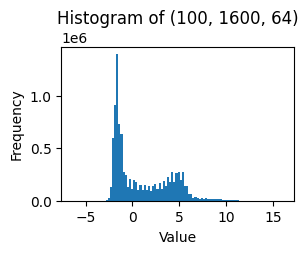

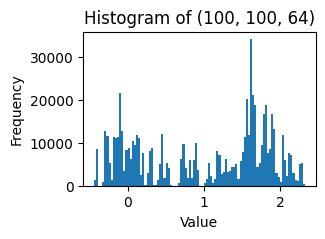

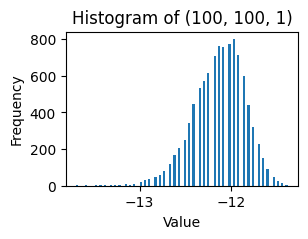

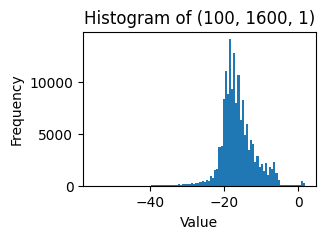

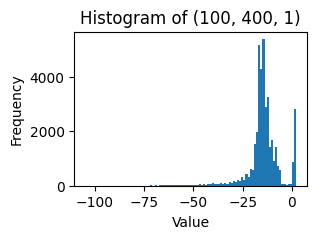

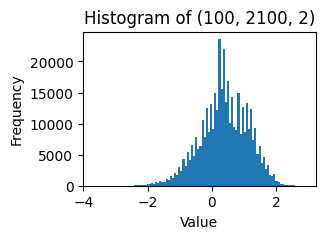

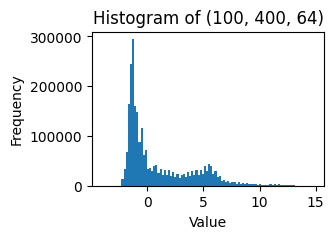

In [5]:
input_tensors = []
for i in range(7):
    input_tensors.append(np.load(f"head_uint8_saved_model/input_{i}.npy"))
    
for i in input_tensors:
    print(i.shape, i.min(), i.max())
    
for i in input_tensors:
    plt.figure(figsize=(3, 2))
    plt.hist(i.flatten(), bins=100)
    plt.title(f"Histogram of {i.shape}")
    plt.xlabel("Value")
    plt.ylabel("Frequency")

[(100, 100, 1), (100, 1600, 1), (100, 400, 1)]


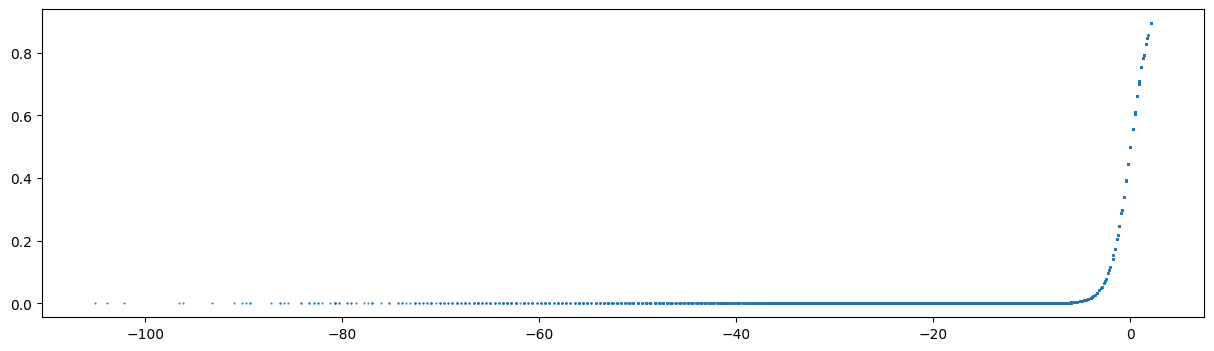

In [6]:
model_inputs = input_tensors[2:5]
print([i.shape for i in model_inputs])  # Check shapes of inputs

model = Dummy()
y = model(*[torch.Tensor(i) for i in model_inputs])

gt_x = np.hstack([i for i in model_inputs]).flatten()
gt_y = y.flatten()

plt.figure(figsize=(15, 4))
plt.plot(gt_x, gt_y, ".", markersize=1)

In [7]:
gt_x.min(), gt_x.max()

(-105.1385, 2.1369615)

In [8]:
LIMIT_MIN = gt_x.min()
LIMIT_MAX = gt_x.max()
LIMIT_MIN, LIMIT_MAX

# LIMIT_MIN = -50
# LIMIT_MAX = 5
# LIMIT_MIN, LIMIT_MAX


(-105.1385, 2.1369615)

In [9]:
model2onnx(
    "dummy_multi_input_saved_model/dummy.onnx",
    model,
    [model_inputs[0][:1], model_inputs[1][:1], model_inputs[2][:1]],
    simplify=True
)

In [10]:
np.array([[[0]]]).shape

(1, 1, 1)

In [11]:
[i.shape for i in model_inputs]  # Check shapes of inputs

[(100, 100, 1), (100, 1600, 1), (100, 400, 1)]

In [12]:
def norm_data(x: np.ndarray, limit_min: float = LIMIT_MIN, limit_max: float = LIMIT_MAX) -> np.ndarray:
    """
    Normalize data to the range [0, 255].
    """
    return np.clip((x - limit_min) / (limit_max - limit_min), 0, 1) * 255

x0 = norm_data(model_inputs[0])
x1 = norm_data(model_inputs[1])
x2 = norm_data(model_inputs[2])


MEAN = 255 * np.abs(LIMIT_MIN) / (LIMIT_MAX - LIMIT_MIN)
STD = 255 / (LIMIT_MAX - LIMIT_MIN)

np.save("dummy_multi_input_saved_model/x0.npy", x0)
np.save("dummy_multi_input_saved_model/x1.npy", x1)
np.save("dummy_multi_input_saved_model/x2.npy", x2)

onnx2tf.convert(
    input_onnx_file_path="dummy_multi_input_saved_model/dummy.onnx",
    output_folder_path="dummy_multi_input_saved_model",
    not_use_onnxsim=True,
    verbosity=True,
    keep_ncw_or_nchw_or_ncdhw_input_names=[f"input_{i}" for i in range(3)],
    copy_onnx_input_output_names_to_tflite=True,
    output_integer_quantized_tflite=True,
    input_output_quant_dtype="uint8",
    quant_type="per-tensor",
    custom_input_op_name_np_data_path=[
        ["input_0", "dummy_multi_input_saved_model/x0.npy", [[[MEAN]]], [[[STD]]]],
        ["input_1", "dummy_multi_input_saved_model/x1.npy", [[[MEAN]]], [[[STD]]]],
        ["input_2", "dummy_multi_input_saved_model/x2.npy", [[[MEAN]]], [[[STD]]]],
    ],
    disable_group_convolution=True,  # for end-to-end model compatibility
    enable_batchmatmul_unfold=True,  # for end-to-end model compatibility
)


Automatic generation of each OP name started ========================================
Automatic generation of each OP name complete!

Model loaded ========================================================================

Model conversion started ============================================================
 index: 1 Got: 1 Expected: 400
 index: 2 Got: 400 Expected: 1
 Please fix either the inputs/outputs or the model.
saved_model output started ==========================================================
saved_model output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Float32 tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Float16 tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && t

I0000 00:00:1753973819.981877 1122583 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753973820.005582 1122583 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753973820.005607 1122583 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
I0000 00:00:1753973820.033456 1122583 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753973820.049572 1122583 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753973820.049584 1122583 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
I0000 00:00:1753973820.076006 1122583 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0
W0000 00:00:1753973820.091581 1122583 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753973820.091592 1122583 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.
W0000 00:00:1753973820.19

wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
INT8 Quantization tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Full INT8 Quantization tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
INT8 Quantization with int16 activations tflite output complete!
wget https://github.com/PINTO0309/onnx2tf/releases/download/1.16.31/flatc.tar.gz && tar -zxvf flatc.tar.gz && sudo chmod +x flatc && sudo mv flatc /usr/bin/
Full INT8 Quantization with int16 activations tflite output complete!


W0000 00:00:1753973820.588645 1122583 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1753973820.588658 1122583 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.


In [13]:
print(f"mean = {MEAN}, std = {STD}")

mean = 249.92031504019434, std = 2.3770581052626487


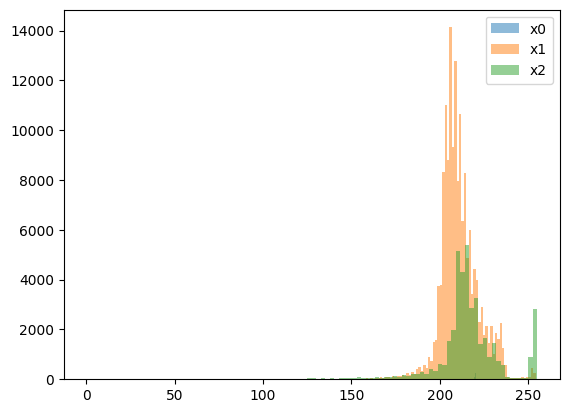

In [14]:
plt.hist(x0.flatten(), bins=100, alpha=0.5, label='x0');
plt.hist(x1.flatten(), bins=100, alpha=0.5, label='x1');
plt.hist(x2.flatten(), bins=100, alpha=0.5, label='x2');
plt.legend();

In [15]:
model_fp32 = load_model("dummy_multi_input_saved_model/dummy_float32.tflite")
model_uint8 = load_model("dummy_multi_input_saved_model/dummy_full_integer_quant.tflite")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [16]:
def idx_from_name(name: str) -> int:
    """
    Extract index from input name.
    """
    return int(name.split('_')[-1].replace(':0', ''))

def infer(model, x, dequantize=True):
    input_details = model.get_input_details()
    output_details = model.get_output_details()[0]

    for input_detail in input_details:
        idx = idx_from_name(input_detail['name'])
        model.set_tensor(input_detail['index'], x[idx])
    model.invoke()
    outputs = model.get_tensor(output_details['index'])

    scale, zero_point = output_details['quantization']
    if scale != 0.0 and dequantize:
        print(f"Dequantizing with scale={scale}, zero_point={zero_point}")
        outputs = (outputs.astype(np.float32) - zero_point) * scale  # re-scale

    return outputs

Dequantizing with scale=0.00390625, zero_point=0


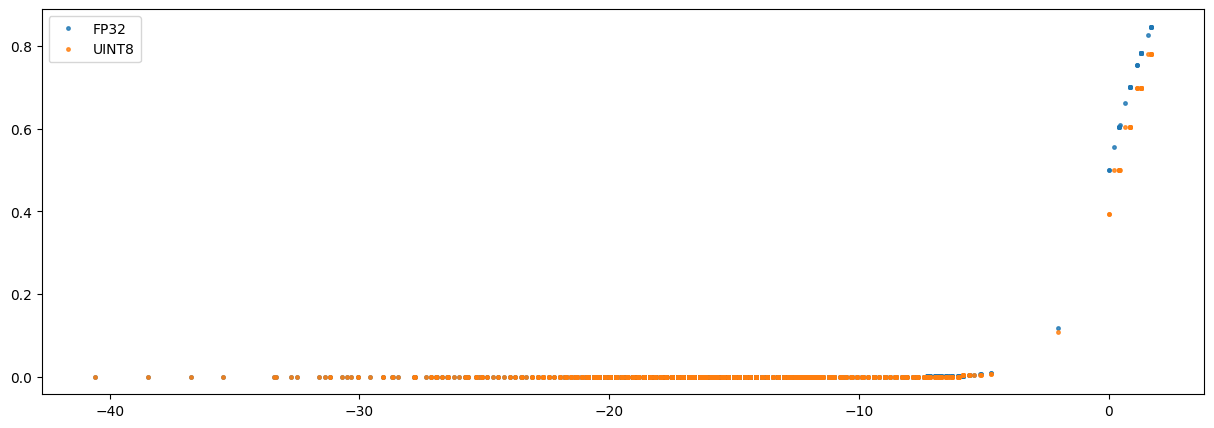

In [17]:
x_inputs = [i[:1] for i in model_inputs]

x_inputs_norm = [norm_data(i).astype(np.uint8) for i in x_inputs]

y_fp32 = infer(model_fp32, x_inputs)
y_uint8 = infer(model_uint8, x_inputs_norm)

plt.figure(figsize=(15, 5))
plt.plot(np.hstack(x_inputs).flatten(), y_fp32.flatten(), '.', markersize=5, alpha=0.8, label='FP32')
plt.plot(np.hstack(x_inputs).flatten(), y_uint8.flatten(), '.', markersize=5, alpha=0.8, label='UINT8')


plt.legend()